# P6. Operasi Morfologi, Komponen Terhubung, dan Modul `bercak.py`
**Praktikum P5-P6 Computer Vision, studi kasus SIMUTEH** | Teknik Informatika UMMI

Isi notebook: **Bagian 3** (morfologi pada citra biner, eksperimen SE), **Bagian 4** (komponen terhubung, pengukuran, penyaringan) dan **Bagian 5** (modul `src/bercak.py`, evaluasi, analisis kesalahan, README dan ZIP).

In [ ]:
# ===== Identitas dan lingkungan (jalankan paling awal) =====
import os, sys
NAMA, NIM, KELAS = "Hisham", "2330511007", "7A"      # ganti KELAS sesuai kelas Anda
SEED = int(NIM[-4:])                                   # 4 digit terakhir NIM -> 1007

try:                                                   # di Colab: simpan kerja di Google Drive
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = f"/content/drive/MyDrive/simuteh-{NIM}"
except ImportError:                                    # di komputer sendiri
    cwd = os.getcwd()
    ROOT = os.path.dirname(cwd) if os.path.basename(cwd) == "notebook" else os.path.abspath(f"simuteh-{NIM}")

for sub in ["notebook", "src", "hasil", "laporan"]:
    os.makedirs(f"{ROOT}/{sub}", exist_ok=True)
os.chdir(f"{ROOT}/notebook")
print("Folder kerja:", os.getcwd(), "| SEED =", SEED)

Mounted at /content/drive
Folder kerja: /content/drive/MyDrive/simuteh-2330511007/notebook | SEED = 1007


In [ ]:
# ===== Cek prasyarat dari Evaluasi P1-P4 dan P5 =====
wajib = ["../src/utils_cv.py", "../src/praproses.py", "../src/utils_tepi.py",
         "../hasil/param_praproses.json", "../data/sintetis/label.csv"]
hilang = [p for p in wajib if not os.path.exists(p)]
assert not hilang, f"Belum ada: {hilang}. Jalankan B1-B5 dan P5_tepi (Run all) di akun dan folder yang sama dulu."
assert len(os.listdir("../data/sintetis/citra")) == 60, "Dataset harus berisi 60 citra (SEED 1007)."
print("Prasyarat dari B1-B5 dan P5 lengkap.")

Prasyarat dari B1-B5 dan P5 lengkap.


In [ ]:
# ===== Impor pustaka dan fungsi bantu =====
sys.path.append("../src")
import time, json, shutil
import cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import tepi_acuan, skor_tepi, iou, mask_daun_awal, bercak_awal
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)

PARAM = json.load(open("../hasil/param_praproses.json"))    # praproses final dari Evaluasi P1-P4
label = pd.read_csv("../data/sintetis/label.csv")
URUTAN = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]
KELAS_ACUAN = {"sehat": "Sehat", "ringan": "Bercak Ringan", "berat": "Bercak Berat"}

def muat(nama):
    """Mengembalikan (citra, mask_daun, mask_bercak) untuk satu berkas."""
    img = baca(f"../data/sintetis/citra/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    """Sama dengan Kode 1.3 (P5): Gaussian lalu cv2.Canny."""
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)
    return cv2.Canny(g, lo, hi)

def jumlah_komponen(m, konek=8):
    """Jumlah komponen terhubung (latar tidak dihitung)."""
    return cv2.connectedComponents((m > 0).astype(np.uint8), connectivity=konek)[0] - 1

# Semua 60 citra dimuat dan dipraproses SEKALI; mask daun awal dihitung sekali; bercak awal untuk k = 3, 4, 6
DATA = {}
for nama in label.nama_file:
    img, md, mb = muat(nama)
    pra = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra)
    DATA[nama] = dict(img=img, md=md, mb=mb, pra=pra, m_daun=m_daun,
                      b0={k: bercak_awal(pra, m_daun, kanal=2, k=k) for k in (3, 4, 6)})
print(len(DATA), "citra siap | praproses:", PARAM)

60 citra siap | praproses: {'lebar': 640, 'gamma': 'auto', 'gamma_terang': 1.6, 'gamma_gelap': 1.0, 'clahe_clip': 1.0, 'clahe_tile': 4, 'clahe_otomatis': True, 'batas_tidak_rata': 0.65, 'penapis': 'median', 'kernel': 3, 'sigma': 1.0, 'tajam_k': 0.0}


## Bagian 3. Operasi morfologi pada citra biner

### Langkah 3.2 Citra biner awal: seberapa kasar sebelum dibersihkan

,citra,IoU daun awal,komponen bercak awal,komponen acuan,IoU bercak awal
0,teh_041.png,0.998,135,7,0.807
1,teh_021.png,0.998,229,1,0.195
2,teh_011.png,0.998,174,0,-


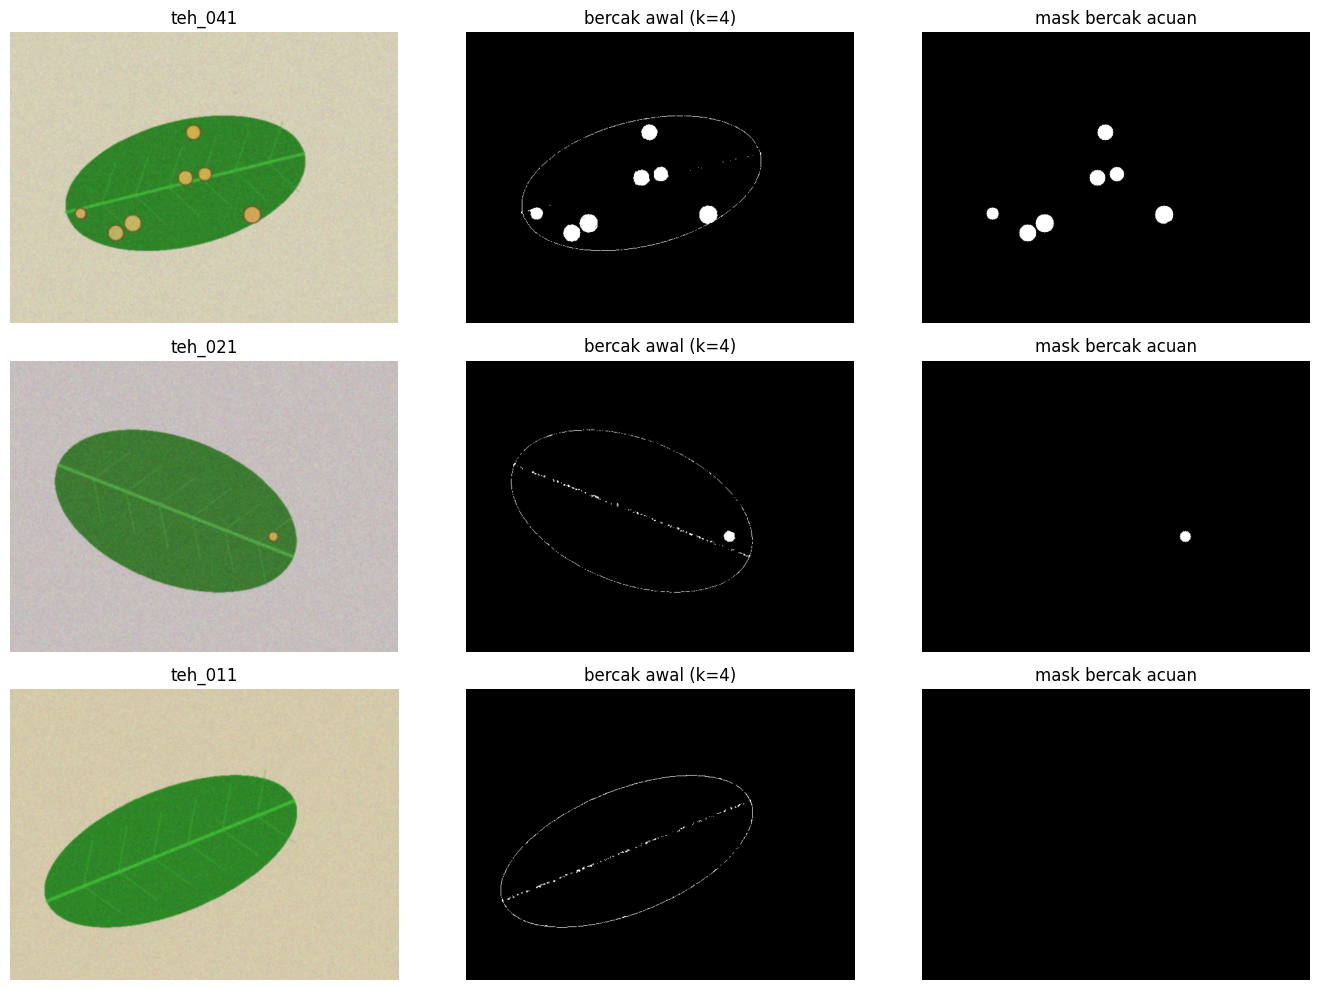

In [ ]:
baris, panel, judul = [], [], []
for nama in ["teh_041.png", "teh_021.png", "teh_011.png"]:          # berat, ringan, sehat
    D = DATA[nama]
    b0 = D["b0"][4]
    baris.append([nama, round(iou(D["m_daun"], D["md"]), 3), jumlah_komponen(b0), jumlah_komponen(D["mb"]),
                  round(iou(b0, D["mb"]), 3) if D["mb"].any() else "-"])
    panel += [D["pra"], b0, D["mb"]]; judul += [nama[:7], "bercak awal (k=4)", "mask bercak acuan"]
tab31 = pd.DataFrame(baris, columns=["citra", "IoU daun awal", "komponen bercak awal", "komponen acuan", "IoU bercak awal"])
display(tab31); tab31.to_csv("../hasil/p6_kode31.csv", index=False)
tampil(panel, judul, baris=3, ukuran=(14, 10))
plt.savefig("../hasil/p6_bercak_awal.png", dpi=110); plt.show()

### Langkah 3.3 Enam operasi dengan SE elips 5 x 5

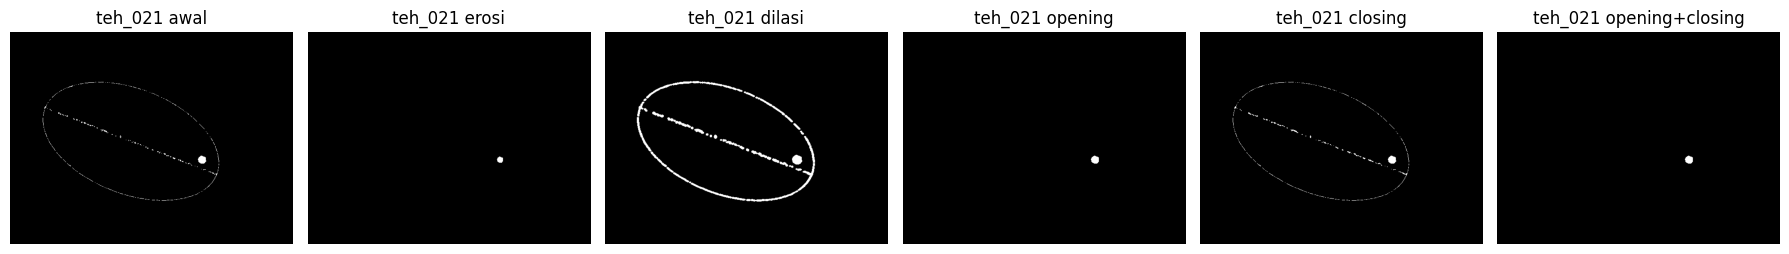

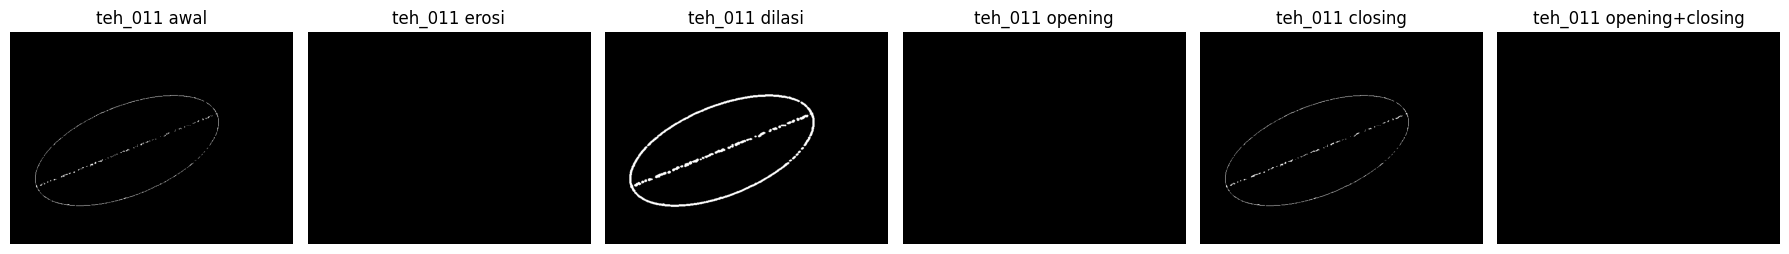

,citra,operasi,komponen,piksel,IoU
0,teh_021.png,awal,229,1259,0.195
1,teh_021.png,erosi,1,151,0.597
2,teh_021.png,dilasi,25,6859,0.037
3,teh_021.png,opening,1,254,0.943
4,teh_021.png,closing,200,1355,0.181
5,teh_021.png,opening+closing,1,254,0.943
6,teh_011.png,awal,174,1234,-
7,teh_011.png,erosi,0,0,-
8,teh_011.png,dilasi,25,6878,-
9,teh_011.png,opening,0,0,-


In [ ]:
SE = lambda k, bentuk=cv2.MORPH_ELLIPSE: cv2.getStructuringElement(bentuk, (k, k))

def operasi(b, se):
    """Mengembalikan kamus: citra awal dan lima hasil operasi morfologi."""
    buka = cv2.morphologyEx(b, cv2.MORPH_OPEN, se)
    return {"awal": b,
            "erosi": cv2.erode(b, se),
            "dilasi": cv2.dilate(b, se),
            "opening": buka,
            "closing": cv2.morphologyEx(b, cv2.MORPH_CLOSE, se),
            "opening+closing": cv2.morphologyEx(buka, cv2.MORPH_CLOSE, se)}

baris = []
for nama in ["teh_021.png", "teh_011.png"]:                          # ringan, sehat
    D = DATA[nama]
    hasil = operasi(D["b0"][4], SE(5))
    for nm, m in hasil.items():
        baris.append([nama, nm, jumlah_komponen(m), int((m > 0).sum()),
                      round(iou(m, D["mb"]), 3) if D["mb"].any() else "-"])
    tampil(list(hasil.values()), [f"{nama[:7]} {nm}" for nm in hasil], ukuran=(18, 3))
    plt.savefig(f"../hasil/p6_operasi_{nama[:7]}.png", dpi=110); plt.show()
tab32 = pd.DataFrame(baris, columns=["citra", "operasi", "komponen", "piksel", "IoU"])
display(tab32); tab32.to_csv("../hasil/p6_kode32.csv", index=False)

### Langkah 3.4 Eksperimen k, bentuk SE, dan ukuran SE (60 citra)

In [ ]:
BENTUK = {"persegi": cv2.MORPH_RECT, "elips": cv2.MORPH_ELLIPSE, "silang": cv2.MORPH_CROSS}
baris = []
for _, d in label.iterrows():
    D = DATA[d.nama_file]
    n_acuan = jumlah_komponen(D["mb"])
    for k in (3, 4, 6):
        b0 = D["b0"][k]
        for nb, kb in BENTUK.items():
            for uk in (3, 5, 7):
                se = SE(uk, kb)
                m = cv2.morphologyEx(cv2.morphologyEx(b0, cv2.MORPH_OPEN, se), cv2.MORPH_CLOSE, se)
                baris.append([d.kelas, k, nb, uk, abs(jumlah_komponen(m) - n_acuan),
                              iou(m, D["mb"]) if D["mb"].any() else np.nan])
eks = pd.DataFrame(baris, columns=["kelas", "k", "bentuk", "ukuran", "galat_jumlah", "IoU"])
eks.to_csv("../hasil/p6_eksperimen_se.csv", index=False)

# Tabel 9: k = 4
t4 = eks[eks.k == 4]
idx = pd.MultiIndex.from_product([["persegi", "elips", "silang"], [3, 5, 7]], names=["bentuk", "ukuran"])
tab9 = pd.concat([t4.pivot_table(index=["bentuk", "ukuran"], columns="kelas", values="IoU")[["berat", "ringan"]]
                    .add_prefix("IoU_"),
                  t4.pivot_table(index=["bentuk", "ukuran"], columns="kelas", values="galat_jumlah")[["berat", "ringan", "sehat"]]
                    .add_prefix("galat_")], axis=1).reindex(idx).round(2)
print("Tabel 9: eksperimen SE untuk k = 4"); display(tab9); tab9.to_csv("../hasil/p6_tabel9_se.csv")

# Ringkasan untuk ketiga nilai k (rerata per kelas), untuk P3.4
ring = eks.pivot_table(index=["k", "bentuk", "ukuran"], columns="kelas", values=["galat_jumlah", "IoU"]).round(2)
print("Semua k, bentuk, ukuran"); display(ring)

Tabel 9: eksperimen SE untuk k = 4


kelas           IoU_berat  IoU_ringan  galat_berat  galat_ringan  galat_sehat
bentuk  ukuran                                                               
persegi 3            0.77        0.49         1.20          4.50         7.20
        5            0.81        0.64         2.30          2.15         0.15
        7            0.83        0.65         0.40          0.40         0.00
elips   3            0.77        0.45         3.65          9.60        14.00
        5            0.78        0.55         2.40          2.90         2.25
        7            0.83        0.71         0.80          0.45         0.00
silang  3            0.77        0.45         3.65          9.60        14.00
        5            0.78        0.54         2.55          4.60         4.40
        7            0.82        0.66         1.85          1.20         0.05

Semua k, bentuk, ukuran


IoU        galat_jumlah              
kelas            berat ringan        berat ringan  sehat
k bentuk  ukuran                                        
3 elips   3       0.73   0.29        15.90  17.30  17.95
          5       0.77   0.43         1.80   4.40   4.80
          7       0.81   0.64         2.05   2.60   0.20
  persegi 3       0.74   0.33         7.65   7.10   9.30
          5       0.79   0.54         2.30   2.70   2.00
          7       0.84   0.68         0.45   0.30   0.00
  silang  3       0.73   0.29        15.90  17.30  17.95
          5       0.77   0.40         3.50   6.45   7.80
          7       0.81   0.57         3.05   5.15   1.50
4 elips   3       0.77   0.45         3.65   9.60  14.00
          5       0.78   0.55         2.40   2.90   2.25
          7       0.83   0.71         0.80   0.45   0.00
  persegi 3       0.77   0.49         1.20   4.50   7.20
          5       0.81   0.64         2.30   2.15   0.15
          7       0.83   0.65         0.40   0.40   0.00
  silang  3       0.77   0.45         3.65   9.60  14.00
          5       0.78   0.54         2.55   4.60   4.40
          7       0.82   0.66         1.85   1.20   0.05
6 elips   3       0.77   0.57         5.35   7.35   5.15
          5       0.79   0.64         1.20   1.90   0.00
          7       0.80   0.68         0.40   0.15   0.00
  persegi 3       0.78   0.60         3.25   3.55   0.70
          5       0.79   0.68         0.35   0.25   0.00
          7       0.78   0.58         0.40   0.50   0.00
  silang  3       0.77   0.57         5.35   7.35   5.15
          5       0.79   0.63         2.05   2.90   0.10
          7       0.78   0.63         0.30   0.05   0.00

### Langkah 3.5 Gradien morfologi dibandingkan dengan Canny (batas daun)

In [ ]:
baris = []
for _, d in label.iterrows():
    D = DATA[d.nama_file]
    grad = cv2.morphologyEx(D["m_daun"], cv2.MORPH_GRADIENT, SE(3))            # dilasi - erosi
    can = tepi_canny(cv2.cvtColor(D["pra"], cv2.COLOR_BGR2GRAY))
    ad = tepi_acuan(D["md"])
    baris.append([d.kondisi_cahaya, skor_tepi(grad, ad)[2], skor_tepi(can, ad)[2]])
tab_grad = (pd.DataFrame(baris, columns=["kondisi", "F1_gradien_morfologi", "F1_Canny"])
            .groupby("kondisi").mean().reindex(URUTAN).round(3))
display(tab_grad); tab_grad.to_csv("../hasil/p6_gradien_vs_canny.csv")

,F1_gradien_morfologi,F1_Canny
kondisi,,
normal,0.992,0.917
gelap,0.991,0.870
terang,0.991,0.934
kontras_rendah,0.514,0.000
bayangan,0.917,0.877


### Langkah 3.6 Panel elemen penstruktur (SE) persegi, elips, silang berukuran 3, 5, 7

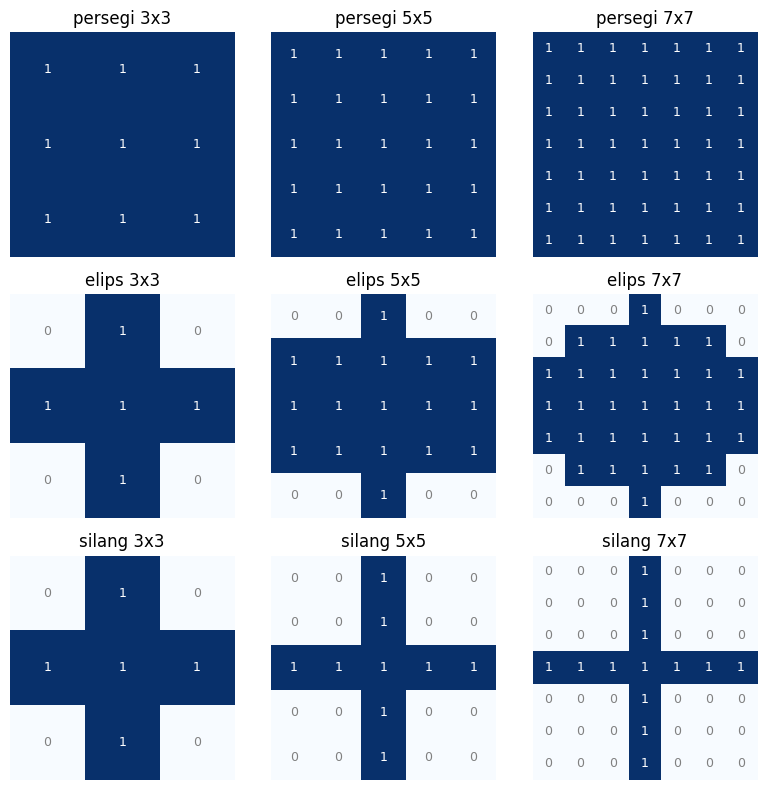

SE elips 3x3 identik dengan silang 3x3: True
Jumlah piksel 1 pada SE 5x5 -> persegi: 25 | elips: 17 | silang: 9


In [ ]:
fig, ax = plt.subplots(3, 3, figsize=(8, 8))
for i, (nb, kb) in enumerate(BENTUK.items()):
    for j, uk in enumerate((3, 5, 7)):
        se = SE(uk, kb)
        ax[i, j].imshow(se, cmap="Blues", vmin=0, vmax=1)
        for (y, x), v in np.ndenumerate(se):
            ax[i, j].text(x, y, int(v), ha="center", va="center", fontsize=9, color="white" if v else "gray")
        ax[i, j].set_title(f"{nb} {uk}x{uk}"); ax[i, j].axis("off")
plt.tight_layout(); plt.savefig("../hasil/p6_panel_se.png", dpi=120); plt.show()
print("SE elips 3x3 identik dengan silang 3x3:", np.array_equal(SE(3, cv2.MORPH_ELLIPSE), SE(3, cv2.MORPH_CROSS)))
print("Jumlah piksel 1 pada SE 5x5 -> persegi:", int(SE(5, cv2.MORPH_RECT).sum()),
      "| elips:", int(SE(5, cv2.MORPH_ELLIPSE).sum()), "| silang:", int(SE(5, cv2.MORPH_CROSS).sum()))

## Bagian 4. Komponen terhubung dan pengukuran bercak

### Langkah 4.2 Label dan ukur setiap bercak (teh_041)

konektivitas 4: 6 komponen
konektivitas 8: 6 komponen
Tabel 10: ukuran setiap bercak pada teh_041


,label,luas_px,luas_mm2,keliling_px,kebulatan,rasio_aspek,cx,cy
0,1,534,102.21,85.8,0.91,1.04,302,164
1,2,453,86.71,77.4,0.95,1.00,321,233
2,3,553,105.85,87.6,0.91,1.02,288,240
3,4,711,136.09,98.7,0.92,1.03,399,300
4,5,328,62.78,67.1,0.92,1.02,116,298
5,6,1334,255.34,193.3,0.45,2.01,188,322


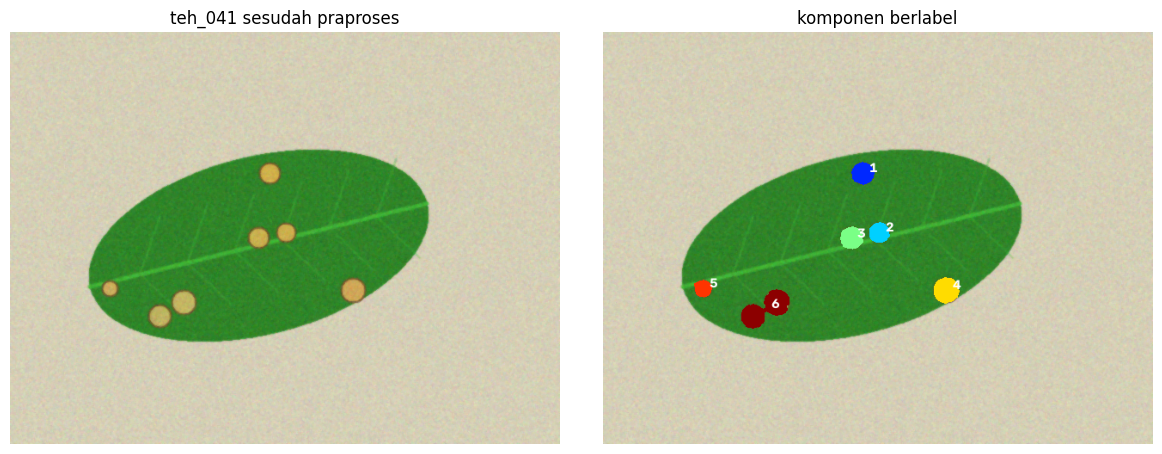

In [ ]:
MM_PER_PX = 0.4375          # dari lembar hitung P2: Z = 200 mm, lebar kerja 640 px

def ukur_komponen(m, konek=8):
    """Melabeli komponen terhubung lalu mengukur luas, keliling, kebulatan, dan rasio aspek setiap komponen."""
    n, lbl, st, cen = cv2.connectedComponentsWithStats((m > 0).astype(np.uint8), connectivity=konek)
    baris = []
    for i in range(1, n):
        x, y, w, h, A = (int(v) for v in st[i])
        potong = (lbl[y:y + h, x:x + w] == i).astype(np.uint8)       # hanya kotak pembatas, agar cepat
        kontur, _ = cv2.findContours(potong, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        keliling = cv2.arcLength(kontur[0], True)
        kebulatan = 0.0 if keliling == 0 else 4 * np.pi * A / keliling ** 2
        sa, sb = cv2.minAreaRect(kontur[0])[1]
        rasio = max(sa, sb) / max(min(sa, sb), 1)
        baris.append([i, A, round(A * MM_PER_PX ** 2, 2), round(keliling, 1), round(kebulatan, 2),
                      round(rasio, 2), int(cen[i][0]), int(cen[i][1])])
    kolom = ["label", "luas_px", "luas_mm2", "keliling_px", "kebulatan", "rasio_aspek", "cx", "cy"]
    return pd.DataFrame(baris, columns=kolom), lbl

def bersihkan(b, uk=5):
    """Opening lalu closing dengan SE elips (pembersihan standar P6)."""
    return cv2.morphologyEx(cv2.morphologyEx(b, cv2.MORPH_OPEN, SE(uk)), cv2.MORPH_CLOSE, SE(uk))

D = DATA["teh_041.png"]
bersih = bersihkan(D["b0"][4])
for konek in (4, 8):
    print(f"konektivitas {konek}: {jumlah_komponen(bersih, konek)} komponen")
tabel_kom, lbl = ukur_komponen(bersih)
print("Tabel 10: ukuran setiap bercak pada teh_041"); display(tabel_kom)
tabel_kom.to_csv("../hasil/p6_tabel10_teh041.csv", index=False)

warna = cv2.applyColorMap((lbl * (255 // max(lbl.max(), 1))).astype(np.uint8), cv2.COLORMAP_JET)
warna[lbl == 0] = D["pra"][lbl == 0]
for _, r in tabel_kom.iterrows():
    cv2.putText(warna, str(int(r.label)), (int(r.cx) + 8, int(r.cy)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 2)
tampil([D["pra"], warna], ["teh_041 sesudah praproses", "komponen berlabel"], ukuran=(12, 4.5))
plt.savefig("../hasil/p6_teh041_berlabel.png", dpi=120); plt.show()

In [ ]:
# Angka bantu untuk P4.4: luas total bercak teh_041 pada tiap tahap dibandingkan dengan mask acuan
b_awal = D["b0"][4]
b_buka = cv2.morphologyEx(b_awal, cv2.MORPH_OPEN, SE(5))
b_tutup = cv2.morphologyEx(b_buka, cv2.MORPH_CLOSE, SE(5))
acuan_px = int((D["mb"] > 0).sum())
tahap = {"bercak awal": b_awal, "sesudah opening": b_buka, "sesudah opening+closing": b_tutup}
baris = [[nm, int((m > 0).sum()), round(100 * ((m > 0).sum() / acuan_px - 1), 1)] for nm, m in tahap.items()]
baris.append(["mask acuan", acuan_px, 0.0])
tab44 = pd.DataFrame(baris, columns=["tahap", "luas_total_px", "selisih_thd_acuan_%"])
display(tab44); tab44.to_csv("../hasil/p6_p44_luas_teh041.csv", index=False)
print("Luas total acuan:", acuan_px, "px =", round(acuan_px * MM_PER_PX ** 2, 1), "mm2")

,tahap,luas_total_px,selisih_thd_acuan_%
0,bercak awal,4691,22.3
1,sesudah opening,3892,1.5
2,sesudah opening+closing,3913,2.0
3,mask acuan,3836,0.0


Luas total acuan: 3836 px = 734.2 mm2


### Langkah 4.3 Aturan penyaringan komponen (60 citra)

In [ ]:
def saring_tabel(tabel_k, luas_min=20, bulat_min=0.5, rasio_maks=1.8):
    """Baris komponen yang lolos tiga syarat: luas, kebulatan, rasio aspek."""
    return tabel_k[(tabel_k.luas_px >= luas_min) & (tabel_k.kebulatan >= bulat_min) & (tabel_k.rasio_aspek <= rasio_maks)]

ATURAN = {"tanpa saring": (0, 0, 99), "luas >= 20": (20, 0, 99),
          "luas + kebulatan": (20, 0.5, 99), "luas + kebulatan + rasio": (20, 0.5, 1.8)}

UKURAN = {}                                   # tabel ukuran semua komponen per citra (dipakai juga di Langkah 4.4)
baris = []
for _, d in label.iterrows():
    D = DATA[d.nama_file]
    UKURAN[d.nama_file] = ukur_komponen(bersihkan(D["b0"][4]))
    n_acuan = jumlah_komponen(D["mb"])
    for nm, (a, b, r) in ATURAN.items():
        baris.append([d.kelas, nm, len(saring_tabel(UKURAN[d.nama_file][0], a, b, r)), n_acuan])
uji = pd.DataFrame(baris, columns=["kelas", "aturan", "jumlah", "acuan"])
uji["galat"] = (uji.jumlah - uji.acuan).abs()

tab11 = uji.pivot_table(index="aturan", columns="kelas", values="galat")[["berat", "ringan", "sehat"]].reindex(list(ATURAN))
tab11["sehat_dgn_bercak_palsu"] = (uji[uji.kelas == "sehat"].assign(palsu=lambda t: t.jumlah > 0)
                                   .groupby("aturan").palsu.sum().reindex(list(ATURAN)))
tab11 = tab11.round(2)
print("Tabel 11: aturan penyaringan"); display(tab11); tab11.to_csv("../hasil/p6_tabel11_saring.csv")

Tabel 11: aturan penyaringan


kelas,berat,ringan,sehat,sehat_dgn_bercak_palsu
aturan,,,,
tanpa saring,2.4,2.90,2.25,5
luas >= 20,1.7,1.80,1.40,4
luas + kebulatan,1.3,1.05,0.80,4
luas + kebulatan + rasio,1.0,0.50,0.40,4


### Langkah 4.4 Dasar ambang penyaringan: komponen benar dan palsu

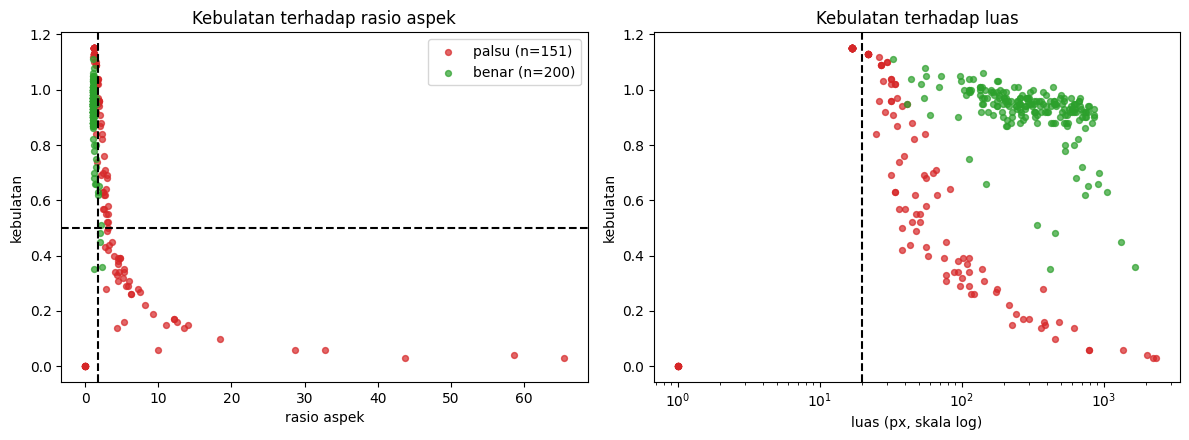

Ringkasan komponen (benar = True)


luas_px              kebulatan              rasio_aspek              
          min median   max       min median   max         min median    max
benar                                                                      
False       1   32.0  2341      0.00   0.84  1.15         0.0   1.70  65.40
True       33  298.0  1668      0.35   0.95  1.11         1.0   1.04   2.28

Komponen palsu yang lolos aturan penuh: 26 | komponen benar yang terbuang: 6


In [ ]:
# Komponen "benar" bila lebih dari separuh pikselnya berada di mask_bercak acuan
semua = []
for nama, (tk, lb) in UKURAN.items():
    if tk.empty:                                                   # citra tanpa komponen sama sekali
        continue
    mb = DATA[nama]["mb"] > 0
    dalam = np.bincount(lb[mb], minlength=lb.max() + 1)           # piksel tiap label yang jatuh di mask acuan
    t = tk.copy()
    t["benar"] = (dalam[t.label.values] / t.luas_px.values) > 0.5
    t["nama"] = nama
    semua.append(t)
semua = pd.concat(semua, ignore_index=True)
semua.to_csv("../hasil/p6_komponen_benar_palsu.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for nilai, wr, nm in [(False, "tab:red", "palsu"), (True, "tab:green", "benar")]:
    s = semua[semua.benar == nilai]
    ax[0].scatter(s.rasio_aspek, s.kebulatan, c=wr, s=18, alpha=0.7, label=f"{nm} (n={len(s)})")
    ax[1].scatter(s.luas_px, s.kebulatan, c=wr, s=18, alpha=0.7, label=nm)
ax[0].axhline(0.5, ls="--", c="k"); ax[0].axvline(1.8, ls="--", c="k")
ax[0].set_xlabel("rasio aspek"); ax[0].set_ylabel("kebulatan"); ax[0].set_title("Kebulatan terhadap rasio aspek"); ax[0].legend()
ax[1].axvline(20, ls="--", c="k"); ax[1].set_xscale("log")
ax[1].set_xlabel("luas (px, skala log)"); ax[1].set_ylabel("kebulatan"); ax[1].set_title("Kebulatan terhadap luas")
plt.tight_layout(); plt.savefig("../hasil/p6_sebar_benar_palsu.png", dpi=120); plt.show()

ringkas = semua.groupby("benar")[["luas_px", "kebulatan", "rasio_aspek"]].agg(["min", "median", "max"]).round(2)
print("Ringkasan komponen (benar = True)"); display(ringkas)
print("Komponen palsu yang lolos aturan penuh:", len(saring_tabel(semua[~semua.benar])),
      "| komponen benar yang terbuang:", len(semua[semua.benar]) - len(saring_tabel(semua[semua.benar])))

## Bagian 5. Integrasi: modul `src/bercak.py`

### Langkah 5.1 Modul (ketujuh TODO terisi)

In [ ]:
%%writefile ../src/bercak.py
"""bercak.py: analisis bercak SIMUTEH (dipakai ulang mulai P7)."""
import json
import cv2
import numpy as np
from utils_tepi import mask_daun_awal, bercak_awal

PARAM_BERCAK = {
    "kanal": 2,            # kanal terpilih (2 = R)
    "k": 4.0,              # ambang median + k x MAD
    "se_bentuk": "elips",  # "elips", "persegi", "silang"
    "se_open": 5,          # ukuran SE opening (0 = tidak dipakai)
    "se_close": 5,         # ukuran SE closing (0 = tidak dipakai)
    "luas_min": 20,        # piksel
    "bulat_min": 0.5,
    "rasio_maks": 1.8,
    "batas_ringan": 0.1,   # persen bercak minimum kelas Ringan
    "batas_berat": 2.0,    # persen bercak minimum kelas Berat
    "mm_per_px": 0.4375,
}

_BENTUK = {"elips": cv2.MORPH_ELLIPSE, "persegi": cv2.MORPH_RECT, "silang": cv2.MORPH_CROSS}


def _se(p, uk):
    return cv2.getStructuringElement(_BENTUK[p["se_bentuk"]], (uk, uk))


def bersihkan(biner, p):
    """Opening membuang titik derau dan potongan tipis; closing menutup celah."""
    hasil = biner
    if p["se_open"] > 0:                                        # TODO 1
        hasil = cv2.morphologyEx(hasil, cv2.MORPH_OPEN, _se(p, p["se_open"]))
    if p["se_close"] > 0:                                       # TODO 2
        hasil = cv2.morphologyEx(hasil, cv2.MORPH_CLOSE, _se(p, p["se_close"]))
    return hasil


def ukur_dan_saring(biner, p):
    """Mengembalikan mask bercak tersaring dan daftar ukuran setiap bercak."""
    # TODO 3: label komponen terhubung, konektivitas 8
    n, lbl, st, cen = cv2.connectedComponentsWithStats((biner > 0).astype(np.uint8), connectivity=8)
    lolos = np.zeros(n, bool)                                   # penanda label yang lolos saring
    daftar = []
    for i in range(1, n):                                       # label 0 = latar
        x, y, w, h, luas = (int(v) for v in st[i])
        # TODO 4: ukuran komponen. Kontur dihitung pada potongan kotak pembatas agar cepat.
        potong = (lbl[y:y + h, x:x + w] == i).astype(np.uint8)
        kontur, _ = cv2.findContours(potong, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        keliling = cv2.arcLength(kontur[0], True)
        kebulatan = 0.0 if keliling == 0 else 4 * np.pi * luas / keliling ** 2
        sisi_a, sisi_b = cv2.minAreaRect(kontur[0])[1]
        rasio = max(sisi_a, sisi_b) / max(min(sisi_a, sisi_b), 1)
        # TODO 5: saring berdasarkan luas, kebulatan, dan rasio aspek
        if luas >= p["luas_min"] and kebulatan >= p["bulat_min"] and rasio <= p["rasio_maks"]:
            lolos[i] = True
            daftar.append({"label": i, "luas_px": luas,
                           "luas_mm2": round(luas * p["mm_per_px"] ** 2, 2),
                           "keliling_px": round(float(keliling), 1),
                           "kebulatan": round(float(kebulatan), 2),
                           "rasio_aspek": round(float(rasio), 2),
                           "cx": int(cen[i][0]), "cy": int(cen[i][1])})
    keluar = (lolos[lbl] * 255).astype(np.uint8)
    return keluar, daftar


def analisis_daun(img_praproses, p=None):
    """Masukan: citra BGR hasil praproses. Keluaran: kamus hasil analisis."""
    p = {**PARAM_BERCAK, **(p or {})}
    m_daun = mask_daun_awal(img_praproses)
    biner = bercak_awal(img_praproses, m_daun, kanal=p["kanal"], k=p["k"])
    m_bercak, daftar = ukur_dan_saring(bersihkan(biner, p), p)
    # TODO 6: persen bercak = luas bercak / luas daun x 100
    luas_daun = int((m_daun > 0).sum())
    persen = 100.0 * int((m_bercak > 0).sum()) / luas_daun if luas_daun > 0 else 0.0
    # TODO 7: kelas dari batas_ringan dan batas_berat
    if persen >= p["batas_berat"]:
        kelas = "Bercak Berat"
    elif persen >= p["batas_ringan"]:
        kelas = "Bercak Ringan"
    else:
        kelas = "Sehat"
    return {"mask_daun": m_daun, "mask_bercak": m_bercak, "jumlah_bercak": len(daftar),
            "persen_bercak": round(float(persen), 3), "kelas": kelas, "bercak": daftar}


def simpan_param(p, path="../hasil/param_bercak.json"):
    with open(path, "w") as f:
        json.dump({**PARAM_BERCAK, **p}, f, indent=2)

Writing ../src/bercak.py


In [ ]:
# Uji cepat modul pada satu citra
import importlib, bercak
importlib.reload(bercak)
h = bercak.analisis_daun(DATA["teh_041.png"]["pra"])
print("teh_041:", h["jumlah_bercak"], "bercak |", h["persen_bercak"], "% |", h["kelas"],
      "| acuan:", label.set_index("nama_file").loc["teh_041.png", "persen_bercak"], "%")
display(pd.DataFrame(h["bercak"]))

teh_041: 5 bercak | 3.93 % | Bercak Berat | acuan: 5.84 %


,label,luas_px,luas_mm2,keliling_px,kebulatan,rasio_aspek,cx,cy
0,1,534,102.21,85.8,0.91,1.04,302,164
1,2,453,86.71,77.4,0.95,1.00,321,233
2,3,553,105.85,87.6,0.91,1.02,288,240
3,4,711,136.09,98.7,0.92,1.03,399,300
4,5,328,62.78,67.1,0.92,1.02,116,298


### Langkah 5.2 Evaluasi menyeluruh (60 citra)

Galat absolut rerata persen bercak: 0.329
Korelasi persen prediksi vs acuan : 0.973
Akurasi kelas                     : 0.933
Daun sehat dinilai berbercak      : 1
Daun berbercak dinilai sehat      : 2
Matriks kekeliruan


prediksi,Sehat,Bercak Ringan,Bercak Berat
acuan,,,
Sehat,19,1,0
Bercak Ringan,2,18,0
Bercak Berat,0,1,19


Akurasi per kondisi cahaya


,benar
kondisi,
normal,1.00
gelap,0.83
terang,1.00
kontras_rendah,0.92
bayangan,0.92


Tabel 12


,Nilai
Galat absolut rerata persen bercak,0.329
Korelasi persen prediksi dan acuan,0.973
Akurasi kelas,0.933
Jumlah daun sehat yang dinilai berbercak,1
Jumlah daun berbercak yang dinilai sehat,2
Kondisi cahaya dengan akurasi terendah,gelap


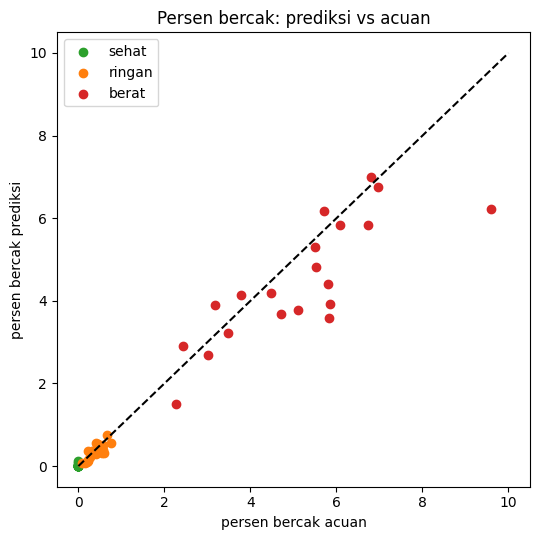

In [ ]:
importlib.reload(bercak)
PB = {}                        # kosong = parameter bawaan; ubah sesuai temuan Anda
bercak.simpan_param(PB)

baris = []
for _, d in label.iterrows():
    D = DATA[d.nama_file]
    h = bercak.analisis_daun(D["pra"], PB)
    baris.append([d.nama_file, d.kelas, d.kondisi_cahaya, d.persen_bercak, h["persen_bercak"],
                  jumlah_komponen(D["mb"]), h["jumlah_bercak"], h["kelas"]])
ev = pd.DataFrame(baris, columns=["nama", "kelas", "kondisi", "persen_acuan", "persen_prediksi",
                                  "jumlah_acuan", "jumlah_prediksi", "kelas_prediksi"])
ev["kelas_acuan"] = ev.kelas.map(KELAS_ACUAN)
ev.to_csv("../hasil/p6_evaluasi_bercak.csv", index=False)

galat = (ev.persen_prediksi - ev.persen_acuan).abs().mean().round(3)
korelasi = ev[["persen_prediksi", "persen_acuan"]].corr().iloc[0, 1].round(3)
akurasi = (ev.kelas_prediksi == ev.kelas_acuan).mean().round(3)
sehat_berbercak = int(((ev.kelas_acuan == "Sehat") & (ev.kelas_prediksi != "Sehat")).sum())
berbercak_sehat = int(((ev.kelas_acuan != "Sehat") & (ev.kelas_prediksi == "Sehat")).sum())
akur_kondisi = ev.assign(benar=ev.kelas_prediksi == ev.kelas_acuan).groupby("kondisi").benar.mean().reindex(URUTAN).round(2)

print("Galat absolut rerata persen bercak:", galat)
print("Korelasi persen prediksi vs acuan :", korelasi)
print("Akurasi kelas                     :", akurasi)
print("Daun sehat dinilai berbercak      :", sehat_berbercak)
print("Daun berbercak dinilai sehat      :", berbercak_sehat)
kelas_urut = ["Sehat", "Bercak Ringan", "Bercak Berat"]
print("Matriks kekeliruan"); display(pd.crosstab(ev.kelas_acuan, ev.kelas_prediksi, rownames=["acuan"], colnames=["prediksi"])
                                       .reindex(index=kelas_urut, columns=kelas_urut, fill_value=0))
print("Akurasi per kondisi cahaya"); display(akur_kondisi)

tab12 = pd.DataFrame({"Nilai": [galat, korelasi, akurasi, sehat_berbercak, berbercak_sehat, akur_kondisi.idxmin()]},
                     index=["Galat absolut rerata persen bercak", "Korelasi persen prediksi dan acuan", "Akurasi kelas",
                            "Jumlah daun sehat yang dinilai berbercak", "Jumlah daun berbercak yang dinilai sehat",
                            "Kondisi cahaya dengan akurasi terendah"])
print("Tabel 12"); display(tab12); tab12.to_csv("../hasil/p6_tabel12_ringkasan.csv")

plt.figure(figsize=(5.5, 5.5))
for kl, wr in [("sehat", "tab:green"), ("ringan", "tab:orange"), ("berat", "tab:red")]:
    s = ev[ev.kelas == kl]; plt.scatter(s.persen_acuan, s.persen_prediksi, c=wr, label=kl)
plt.plot([0, 10], [0, 10], "k--"); plt.xlabel("persen bercak acuan"); plt.ylabel("persen bercak prediksi")
plt.legend(); plt.title("Persen bercak: prediksi vs acuan"); plt.tight_layout()
plt.savefig("../hasil/p6_sebar_persen.png", dpi=120); plt.show()

### Langkah 5.3 Analisis kesalahan: citra yang salah kelas

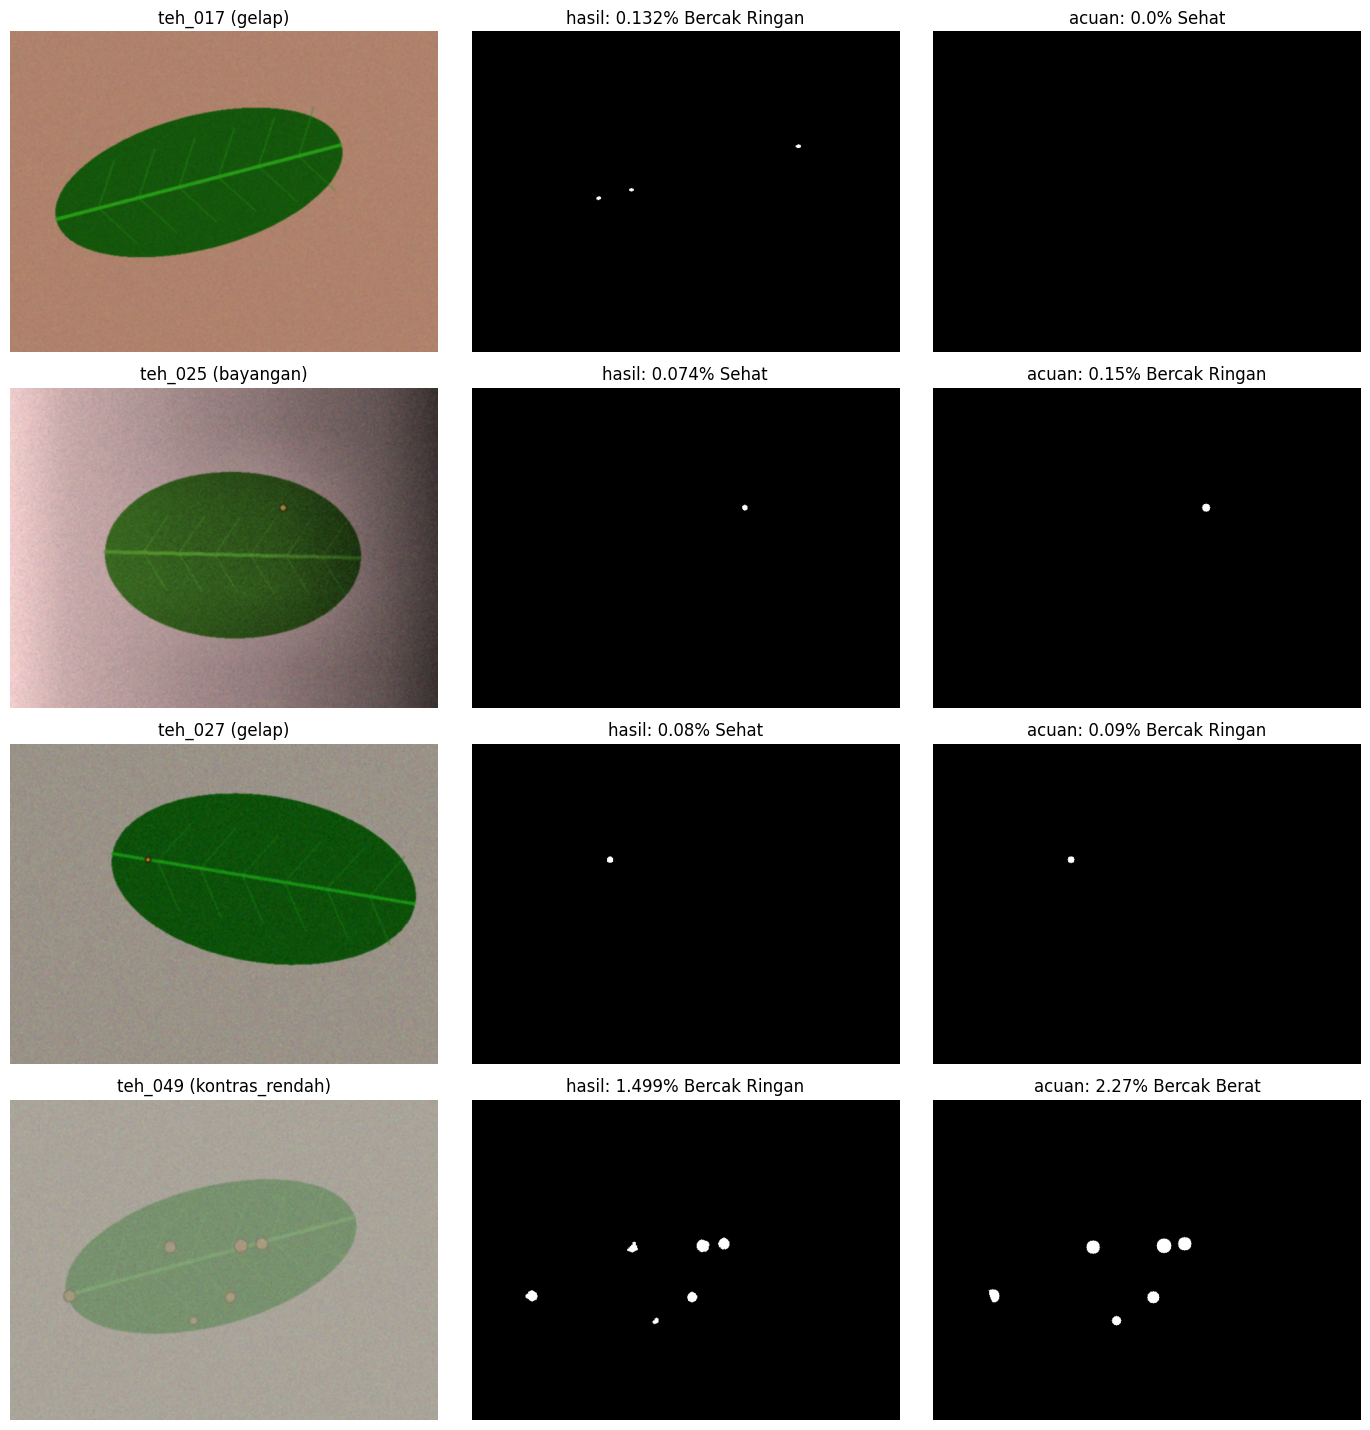

,nama,kondisi,IoU daun awal,komponen b0,komponen sesudah bersih,jumlah hasil,jumlah acuan,luas bercak hasil px,luas bercak acuan px,luas daun awal px,luas daun acuan px
0,teh_017.png,gelap,0.999,98,18,3,0,91,0,68747,68829
1,teh_025.png,bayangan,0.996,77,1,1,1,55,113,74523,74810
2,teh_027.png,gelap,0.999,197,1,1,1,72,81,89646,89624
3,teh_049.png,kontras_rendah,0.948,1370,6,6,6,1097,1648,73175,72577


In [ ]:
salah = ev[ev.kelas_prediksi != ev.kelas_acuan]
panel, judul, baris = [], [], []
for _, r in salah.iterrows():
    D = DATA[r.nama]
    h = bercak.analisis_daun(D["pra"], PB)
    panel += [D["pra"], h["mask_bercak"], D["mb"]]
    judul += [f"{r.nama[:7]} ({r.kondisi})", f"hasil: {r.persen_prediksi}% {r.kelas_prediksi}", f"acuan: {r.persen_acuan}% {r.kelas_acuan}"]
    # angka diagnostik: di tahap mana jumlah/luas komponen berubah
    b0 = bercak_awal(D["pra"], D["m_daun"], kanal=PB.get("kanal", 2), k=PB.get("k", 4.0))
    baris.append([r.nama, r.kondisi, round(iou(D["m_daun"], D["md"]), 3), jumlah_komponen(b0),
                  jumlah_komponen(bersihkan(b0)), r.jumlah_prediksi, r.jumlah_acuan,
                  int((h["mask_bercak"] > 0).sum()), int((D["mb"] > 0).sum()),
                  int((D["m_daun"] > 0).sum()), int((D["md"] > 0).sum())])
tampil(panel, judul, baris=len(salah), ukuran=(14, 3.6 * len(salah)))
plt.savefig("../hasil/p6_citra_salah_kelas.png", dpi=110); plt.show()
diag = pd.DataFrame(baris, columns=["nama", "kondisi", "IoU daun awal", "komponen b0", "komponen sesudah bersih",
                                    "jumlah hasil", "jumlah acuan", "luas bercak hasil px", "luas bercak acuan px",
                                    "luas daun awal px", "luas daun acuan px"])
display(diag); diag.to_csv("../hasil/p6_diagnosis_salah.csv", index=False)

In [ ]:
# Angka bantu untuk P5.2 (batas kelas dari label.csv) dan P5.3 (kondisi cahaya)
print("persen_bercak pada label.csv per kelas"); display(label.groupby("kelas").persen_bercak.agg(["min", "median", "max"]).round(3))
print("Galat absolut persen bercak per kondisi cahaya"); display(
    ev.assign(galat=(ev.persen_prediksi - ev.persen_acuan).abs()).groupby("kondisi").galat.mean().reindex(URUTAN).round(3))
print("Rerata IoU mask daun awal per kondisi"); display(
    pd.Series({k: np.mean([iou(DATA[n]["m_daun"], DATA[n]["md"]) for n in label[label.kondisi_cahaya == k].nama_file])
               for k in URUTAN}).round(3))

persen_bercak pada label.csv per kelas


,min,median,max
kelas,,,
berat,2.27,5.505,9.59
ringan,0.09,0.370,0.75
sehat,0.00,0.000,0.00


Galat absolut persen bercak per kondisi cahaya


,galat
kondisi,
normal,0.321
gelap,0.108
terang,0.138
kontras_rendah,0.570
bayangan,0.507


Rerata IoU mask daun awal per kondisi


,0
normal,0.996
gelap,0.998
terang,0.996
kontras_rendah,0.953
bayangan,0.995


### Langkah 5.4 Bukti untuk Tabel 13 (uji kepekaan parameter)

In [ ]:
def evaluasi_pb(pb):
    """Galat persen, akurasi, daun sehat salah, daun berbercak salah (60 citra) untuk satu set parameter."""
    g, ok, fp, fn = [], [], 0, 0
    for _, d in label.iterrows():
        h = bercak.analisis_daun(DATA[d.nama_file]["pra"], pb)
        g.append(abs(h["persen_bercak"] - d.persen_bercak)); ok.append(h["kelas"] == KELAS_ACUAN[d.kelas])
        fp += int(d.kelas == "sehat" and h["kelas"] != "Sehat"); fn += int(d.kelas != "sehat" and h["kelas"] == "Sehat")
    return [round(np.mean(g), 3), round(np.mean(ok), 3), fp, fn]

varian = {"bawaan": {}, "kanal G": {"kanal": 1}, "kanal B": {"kanal": 0},
          "k = 3": {"k": 3.0}, "k = 5": {"k": 5.0}, "k = 6": {"k": 6.0},
          "SE persegi": {"se_bentuk": "persegi"}, "SE silang": {"se_bentuk": "silang"},
          "opening 3": {"se_open": 3}, "opening 7": {"se_open": 7},
          "tanpa closing": {"se_close": 0}, "closing 7": {"se_close": 7},
          "luas_min 10": {"luas_min": 10}, "luas_min 30": {"luas_min": 30}, "luas_min 40": {"luas_min": 40},
          "bulat_min 0,3": {"bulat_min": 0.3}, "bulat_min 0,7": {"bulat_min": 0.7},
          "rasio_maks 1,4": {"rasio_maks": 1.4}, "rasio_maks 3": {"rasio_maks": 3.0},
          "batas 0,2 / 2,5": {"batas_ringan": 0.2, "batas_berat": 2.5}}
tab13 = pd.DataFrame({nm: evaluasi_pb(pb) for nm, pb in varian.items()},
                     index=["galat_persen", "akurasi", "sehat_dinilai_bercak", "bercak_dinilai_sehat"]).T
print("Uji kepekaan: satu parameter diubah, lainnya bawaan"); display(tab13)
tab13.to_csv("../hasil/p6_tabel13_kepekaan.csv")
print("param_bercak.json yang tersimpan:"); print(open("../hasil/param_bercak.json").read())

Uji kepekaan: satu parameter diubah, lainnya bawaan


,galat_persen,akurasi,sehat_dinilai_bercak,bercak_dinilai_sehat
bawaan,0.329,0.933,1.0,2.0
kanal G,1.319,0.533,0.0,17.0
kanal B,1.210,0.600,0.0,15.0
k = 3,0.344,0.867,3.0,3.0
k = 5,0.358,0.933,0.0,3.0
k = 6,0.399,0.933,0.0,3.0
SE persegi,0.410,0.933,0.0,3.0
SE silang,0.285,0.933,1.0,2.0
opening 3,0.350,0.917,0.0,3.0
opening 7,0.342,0.933,0.0,3.0


param_bercak.json yang tersimpan:
{
  "kanal": 2,
  "k": 4.0,
  "se_bentuk": "elips",
  "se_open": 5,
  "se_close": 5,
  "luas_min": 20,
  "bulat_min": 0.5,
  "rasio_maks": 1.8,
  "batas_ringan": 0.1,
  "batas_berat": 2.0,
  "mm_per_px": 0.4375
}


### Langkah 5.5 README dan ZIP kode

In [ ]:
ringkas_md = tab12.to_string()
readme = f"""# SIMUTEH - Praktikum P5-P6 Computer Vision
Nama: {NAMA} | NIM: {NIM} | Kelas: {KELAS} | SEED: {SEED}

## Cara menjalankan
1. `pip install -r requirements.txt`
2. Dari folder utama: `python src/buat_dataset_sintetis.py` (SEED = {SEED})
3. Jalankan notebook berurutan dengan Restart & Run All: B1 sampai B5, `P5_tepi.ipynb`, lalu `P6_morfologi.ipynb`.

## Memakai analisis bercak
```python
import sys; sys.path.append("src")
from praproses import praproses
import bercak
hasil = bercak.analisis_daun(praproses(citra_bgr, param_praproses))
hasil["jumlah_bercak"], hasil["persen_bercak"], hasil["kelas"]
```
Parameter disimpan di `hasil/param_bercak.json`; praproses di `hasil/param_praproses.json`.

## Alur
praproses -> mask daun awal (Otsu kanal S) -> bercak awal (median + k x MAD, kanal R) -> opening dan closing (SE elips 5) -> komponen terhubung (konektivitas 8) -> saring luas, kebulatan, rasio aspek -> persen bercak dan kelas.

## Ringkasan evaluasi 60 citra (`hasil/p6_evaluasi_bercak.csv`)
```
{ringkas_md}
```
Mask daun dan bercak awal bersifat sementara; diganti metode segmentasi yang lebih kuat pada P7.
"""
open("../README.md", "w").write(readme)
if not os.path.exists("../requirements.txt"):
    import cv2 as _c, numpy as _n, pandas as _p, matplotlib as _m
    open("../requirements.txt", "w").write(f"opencv-python=={_c.__version__}\nnumpy=={_n.__version__}\n"
                                           f"pandas=={_p.__version__}\nmatplotlib=={_m.__version__}\n")

staging = f"{ROOT}/laporan/_zip"
shutil.rmtree(staging, ignore_errors=True)
for sub in ["src", "hasil"]:
    shutil.copytree(f"{ROOT}/{sub}", f"{staging}/{sub}")
os.makedirs(f"{staging}/notebook", exist_ok=True)
for f in ["P5_tepi.ipynb", "P6_morfologi.ipynb"]:                     # notebook P5 dan P6 (B1-B5 sudah terkumpul di evaluasi lalu)
    if os.path.exists(f"{ROOT}/notebook/{f}"): shutil.copy(f"{ROOT}/notebook/{f}", f"{staging}/notebook/{f}")
for f in ["requirements.txt", "README.md"]:
    shutil.copy(f"{ROOT}/{f}", f"{staging}/{f}")
arsip = shutil.make_archive(f"{ROOT}/laporan/Kode_P5-P6_{NIM}", "zip", staging)
shutil.rmtree(staging)
print("ZIP dibuat:", arsip)

ZIP dibuat: /content/drive/MyDrive/simuteh-2330511007/laporan/Kode_P5-P6_2330511007.zip
